<a href="https://colab.research.google.com/github/Sabra7/Ai-usnig-py/blob/main/Lab01_Colab_Setup_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 — Getting Started with Google Colab

**AI · 361CCS-3 / 3251CCS-2**
King Khalid University · College of Computer Science, Abha
Instructor: Mansour Al Ghanim

---

### What you will be able to do after this lab

1. Open, run and save a Colab notebook, and copy it to your own Google Drive.
2. Explain the difference between a **code cell** and a **text cell**, and why *execution order* matters.
3. Check which Python libraries are already installed, and install one that is missing with `pip`.
4. Use `numpy`, `pandas` and `matplotlib` for basic data work.
5. Train and evaluate your first `scikit-learn` model.
6. Get data in and out of Colab (upload a file, mount Drive, download a result).

**Time needed:** about 90 minutes
**Prerequisites:** a Google account. Nothing to install on your own computer.
**Submission:** see the final section, *Exercises*.

> ⚠️ **Before you type anything:** click **File → Save a copy in Drive**.
> You are looking at a read-only copy. If you skip this step, none of your work will be saved.

---
## Part 0 — What is Google Colab, and why are we using it?

**Google Colaboratory** ("Colab") runs Python notebooks on Google's computers, in your browser.
You do not install Python, you do not install libraries, and every student in this course
gets the *same* environment — which means when your code breaks, it breaks for a real
reason and not because of your laptop.

A **notebook** is a document made of *cells*. There are two kinds:

| Cell type | Contains | What happens when you run it |
|---|---|---|
| **Text cell** (Markdown) | Explanations, headings, equations | It renders as formatted text |
| **Code cell** | Python code | The code executes and prints its output below the cell |

Your notebook is connected to a **runtime** (also called a *kernel*): a temporary Linux
machine with Python on it. The runtime holds every variable you have created so far.

### Three facts about the runtime that cause 90% of student problems

1. **The runtime is temporary.** After roughly 90 minutes of inactivity, or 12 hours total,
   it is deleted. Any file you saved *inside Colab* disappears with it. Your **notebook**
   is safe in Drive — the **files** it created are not.
2. **Installed libraries disappear too.** If you `pip install` something, you must run that
   cell again in your next session.
3. **Cells run in the order *you* click them**, not top to bottom. This is the single most
   common source of confusing errors. More on this in Part 2.

---
## Part 1 — Running your first cells

Click the cell below and run it. There are three ways:

- Click the **▶ play button** on the left of the cell
- Press **Shift + Enter** (runs the cell and moves to the next one)
- Press **Ctrl + Enter** (runs the cell and stays where you are)

The first time you run any cell, Colab takes 10–30 seconds to start the runtime. That is normal.

In [ ]:
print("Assalamu alaikum, Machine Learning!")
2 + 2

Notice **two** different things happened:

- `print(...)` explicitly wrote a line of output.
- `2 + 2` was the **last expression** in the cell, so Colab displayed its value (`4`) automatically.

Only the *last* expression is auto-displayed. Run the next cell and see that `10 * 10` is silently discarded.

In [ ]:
10 * 10      # this result is thrown away
99 + 1       # only this one is shown

### Variables live in the runtime, not in the cell

A variable you create in one cell is available in every other cell, because they all share
one Python session.

In [ ]:
student_name = "Moammwd Saeed Alshahrani"
student_id = 445801999

In [ ]:
# A different cell - but the variables are still there
print(f"Name: {student_name}")
print(f"ID:   {student_id}")

Name: Moammwd Saeed Alshahrani
ID:   445801999


---
## Part 2 — Execution order: the trap

Look at the `[ ]` brackets to the left of each code cell. After a cell runs, the bracket
shows a **number**: `[1]`, `[2]`, `[3]`… That number is the order in which cells were
*actually executed*.

This matters enormously. Consider:

In [ ]:
x = 5
print("x is now", x)

In [ ]:
x = x * 2
print("x is now", x)

Run the cell above **three more times**. `x` becomes 10, then 20, then 40, then 80 — the
same cell, the same code, a different answer every time, because the runtime *remembers*.

> ### 🔑 The golden rule
> Before you submit any notebook, run **Runtime → Restart session and run all**.
> If it does not produce the right answer from a clean start, it is not correct —
> even if it "worked" on your screen.

**Useful runtime commands** (in the `Runtime` menu):

| Command | What it does | When to use it |
|---|---|---|
| Run all | Runs every cell top to bottom | Checking your work before submitting |
| Restart session | Wipes all variables, keeps your code | Something is in a weird state |
| Restart session and run all | Both of the above | **Always, before submitting** |
| Disconnect and delete runtime | Completely fresh machine | Broken install, out of memory |

---
## Part 3 — The Python environment

Colab already has Python and most of the libraries this course needs. Let's look at what we have.

Cells that start with `!` are not Python — they are **shell commands**, run on the Linux
machine underneath. This is how you inspect and install things.

In [ ]:
# Which Python version is running?
import sys
print(sys.version)

In [ ]:
# Shell command: ask pip which of our key libraries are installed, and at what version
!pip list 2>/dev/null | grep -E "^(numpy|pandas|scikit-learn|matplotlib|scipy|seaborn) "

### Importing libraries

`pip install` puts a library **on the machine**. `import` brings it **into your Python session**.
They are different steps, and you need both. These import aliases (`np`, `pd`, `plt`) are
near-universal conventions — use them.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

### Installing something that is *not* preinstalled

Everything above came with Colab. Some libraries do not. To install one, use `pip install`.

Two habits worth forming now:

- **`-q`** keeps the output quiet, so you can actually read your notebook.
- **Pin the version** (`package==1.2.3`) in work you want to be reproducible. An
  assignment that ran last month should still run today.

Let's install a small library that Colab does not ship with:

In [ ]:
!pip install -q ucimlrepo

In [ ]:
import ucimlrepo
from importlib.metadata import version

print("ucimlrepo is installed, version", version("ucimlrepo"))

### Upgrading a library you already have

Sometimes you need a newer version than Colab provides:

```python
!pip install -q --upgrade scikit-learn
```

> ⚠️ **After upgrading a library that was already imported, you must restart the runtime**
> (`Runtime → Restart session`) before the new version takes effect. Colab will usually show
> you a "RESTART SESSION" button. Click it. If you do not, you will keep using the old version
> and be very confused.

Do **not** run the upgrade above for this course — the preinstalled scikit-learn is fine,
and upgrading costs you two minutes every session.

---
## Part 4 — NumPy: arrays and vectorised maths

`numpy` gives Python fast, multi-dimensional arrays. Every ML library in this course is
built on top of it, and the matrix notation from **Chapter 3 (Multivariable Linear Regression)**
maps directly onto it.

In [ ]:
import numpy as np

# A 1-D array (a vector)
v = np.array([1, 2, 3, 4, 5])
print("v        =", v)
print("shape    =", v.shape)
print("dtype    =", v.dtype)
print("mean     =", v.mean())
print("std      =", v.std())

In [ ]:
# Vectorised operations: no loop needed, and much faster
print("v * 2    =", v * 2)
print("v ** 2   =", v ** 2)
print("v + v    =", v + v)

In [ ]:
# A 2-D array (a matrix). Convention in ML: rows = samples, columns = features
X = np.array([[2104, 5, 1, 45],
              [1416, 3, 2, 40],
              [1534, 3, 2, 30],
              [ 852, 2, 1, 36]])

print("X shape:", X.shape, " -> 4 samples, 4 features")
print()
print("First column (size in sq ft):", X[:, 0])
print("Second row  (one house)     :", X[1, :])
print()
print("Mean of each feature (column):", X.mean(axis=0))

### Why vectorisation matters

Compare a Python loop against a NumPy operation on one million numbers:

In [ ]:
import time

n = 1_000_000
data = np.random.rand(n)

start = time.time()
total = 0.0
for value in data:
    total += value ** 2
loop_time = time.time() - start

start = time.time()
total_np = (data ** 2).sum()
numpy_time = time.time() - start

print(f"Python loop : {loop_time:.4f} seconds")
print(f"NumPy       : {numpy_time:.4f} seconds")
print(f"NumPy is roughly {loop_time / numpy_time:.0f}x faster")

This is exactly why, in Chapter 3, we write the model as a matrix product
$\hat{Y} = X_b W_b^T$ instead of looping over samples.

In [ ]:
# The matrix form of multivariable linear regression, in one line
X_b = np.c_[np.ones(X.shape[0]), X]          # prepend a column of 1s for the intercept b
W_b = np.array([50.0, 0.1, 10.0, -5.0, -0.5])  # [b, w1, w2, w3, w4] - made-up parameters

Y_hat = X_b @ W_b.T                           # @ is the matrix multiplication operator
print("Predictions for the 4 houses:", np.round(Y_hat, 1))

---
## Part 5 — pandas: working with real datasets

`numpy` arrays have no column names. `pandas` adds them, giving you a **DataFrame** —
a table with labelled columns and mixed data types. This is what you will actually load
real datasets into.

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "size_sqft": [2104, 1416, 1534, 852, 1940, 2200],
    "bedrooms":  [5, 3, 3, 2, 4, 4],
    "floors":    [1, 2, 2, 1, 2, 1],
    "age_years": [45, 40, 30, 36, 25, 15],
    "price_k":   [460, 232, 315, 178, 390, 425],
})

df

,size_sqft,bedrooms,floors,age_years,price_k
0,2104,5,1,45,460
1,1416,3,2,40,232
2,1534,3,2,30,315
3,852,2,1,36,178
4,1940,4,2,25,390
5,2200,4,1,15,425


In [ ]:
print("Shape:", df.shape)
print()
df.info()

Shape: (6, 5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   size_sqft  6 non-null      int64
 1   bedrooms   6 non-null      int64
 2   floors     6 non-null      int64
 3   age_years  6 non-null      int64
 4   price_k    6 non-null      int64
dtypes: int64(5)
memory usage: 372.0 bytes


In [ ]:
# Summary statistics for every numeric column - always look at this first
df.describe()

,size_sqft,bedrooms,floors,age_years,price_k
count,6.000000,6.000000,6.000000,6.000000,6.000000
mean,1674.333333,3.500000,1.500000,31.833333,333.333333
std,508.759144,1.048809,0.547723,10.870449,111.706162
min,852.000000,2.000000,1.000000,15.000000,178.000000
25%,1445.500000,3.000000,1.000000,26.250000,252.750000
50%,1737.000000,3.500000,1.500000,33.000000,352.500000
75%,2063.000000,4.000000,2.000000,39.000000,416.250000
max,2200.000000,5.000000,2.000000,45.000000,460.000000


In [ ]:
# Selecting columns and filtering rows
print("Just the price column:")
print(df["price_k"].tolist())
print()
print("Houses larger than 1500 sq ft:")
df[df["size_sqft"] > 1500]

Just the price column:
[460, 232, 315, 178, 390, 425]

Houses larger than 1500 sq ft:


,size_sqft,bedrooms,floors,age_years,price_k
0,2104,5,1,45,460
2,1534,3,2,30,315
4,1940,4,2,25,390
5,2200,4,1,15,425


In [ ]:
# Creating a new feature from existing ones - this is "feature engineering"
df["price_per_sqft"] = df["price_k"] * 1000 / df["size_sqft"]
df

,size_sqft,bedrooms,floors,age_years,price_k,price_per_sqft
0,2104,5,1,45,460,218.631179
1,1416,3,2,40,232,163.841808
2,1534,3,2,30,315,205.345502
3,852,2,1,36,178,208.920188
4,1940,4,2,25,390,201.030928
5,2200,4,1,15,425,193.181818


---
## Part 6 — matplotlib: seeing your data

Always plot your data before you model it. A scatter plot takes ten seconds and will save
you an hour.

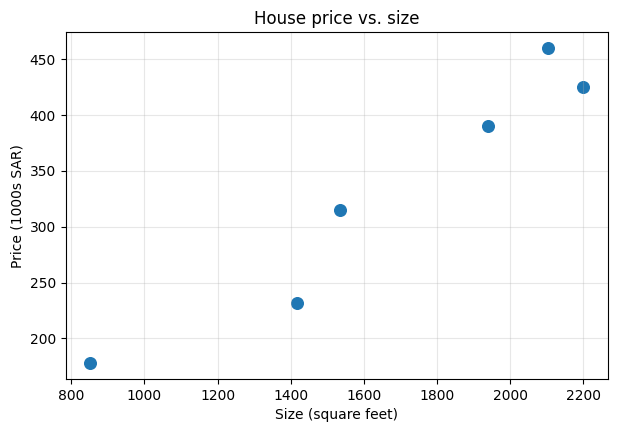

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4.5))
plt.scatter(df["size_sqft"], df["price_k"], s=70)
plt.xlabel("Size (square feet)")
plt.ylabel("Price (1000s SAR)")
plt.title("House price vs. size")
plt.grid(True, alpha=0.3)
plt.show()

The relationship looks roughly linear — which is precisely the assumption behind the
simple linear regression model $f_{w,b}(x) = wx + b$ from **Chapter 2**.

---
## Part 7 — Your first scikit-learn model

`scikit-learn` is the library this whole course runs on. Almost every model in it follows
the same three-step pattern:

```python
model = SomeModel(...)      # 1. create the estimator, set hyperparameters
model.fit(X_train, y_train) # 2. learn the parameters from training data
model.predict(X_new)        # 3. make predictions on new data
```

Learn this pattern once and every algorithm in Chapters 5–10 will feel familiar.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X = iris.data          # the features  (4 measurements per flower)
y = iris.target        # the labels    (which of 3 species)

print("Feature names:", list(X.columns))
print("Class names  :", list(iris.target_names))
print("Shape of X   :", X.shape)
X.head()

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names  : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Shape of X   : (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Splitting the data — and why we must

We evaluate a model on data it has **never seen**. Otherwise we are measuring memorisation,
not generalisation (Chapter 1, and all of Chapter 4).

Note `stratify=y`: it keeps the class proportions the same in the train and test sets.
Always use it for classification.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,     # 25% held out for testing
    random_state=42,    # fixes the shuffle, so your results are reproducible
    stratify=y,         # preserve class balance in both sets
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set    : {X_test.shape[0]} samples")

Training set: 133 samples
Test set    : 45 samples


### Fit and evaluate a k-Nearest Neighbours classifier

kNN is the subject of **Chapter 5**. Here it is in four lines.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

train_accuracy = knn.score(X_train, y_train)
test_accuracy = knn.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy    : {test_accuracy:.3f}")

Training accuracy: 0.789
Test accuracy    : 0.778


In [ ]:
# Predict the species of a new, unseen flower
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns,
)

prediction = knn.predict(new_flower)[0]
probabilities = knn.predict_proba(new_flower)[0]

print("Predicted species:", iris.target_names[prediction])
print()
for name, p in zip(iris.target_names, probabilities):
    print(f"  P({name:<12}) = {p:.2f}")

ValueError: 13 columns passed, passed data had 4 columns

### Does `k` matter?

`n_neighbors` is a **hyperparameter** — we choose it, the algorithm does not learn it.
Chapter 4 is about choosing it properly. Here is a first look at its effect.

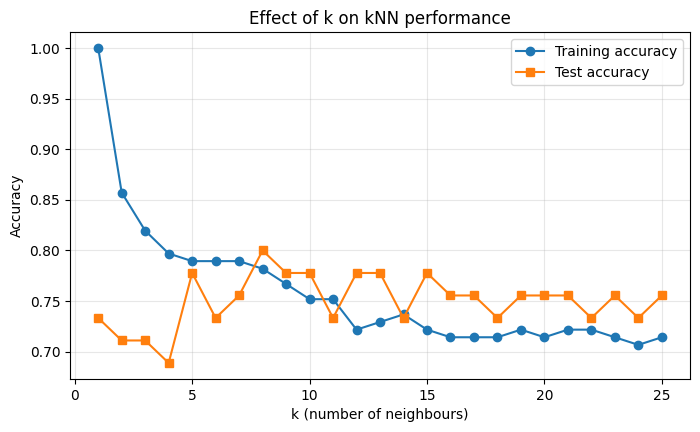

In [ ]:
k_values = range(1, 26)
train_scores, test_scores = [], []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(k_values, train_scores, marker="o", label="Training accuracy")
plt.plot(k_values, test_scores, marker="s", label="Test accuracy")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Effect of k on kNN performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Look at the left edge: at `k = 1` the training accuracy is a perfect 1.0, but the test
accuracy is lower. The model has memorised the training set. That gap is **overfitting**,
and recognising it in a plot like this is a skill you will use all semester.

---
## Part 8 — Getting data in and out of Colab

### 8a. Upload a file from your computer

Running the cell below opens a file picker. Useful for a one-off CSV.
The file lands in `/content/` and **disappears when the runtime restarts**.

```python
from google.colab import files
uploaded = files.upload()
```

### 8b. Mount your Google Drive (recommended for this course)

This makes your entire Drive available as a folder. Files you write there are permanent.

```python
from google.colab import drive
drive.mount('/content/drive')
# Your files are then under /content/drive/MyDrive/
```

You will be asked to authorise access. Only ever do this with **your own** account.

### 8c. Read a CSV straight from a URL

Often the easiest option, and it needs no upload at all:

```python
df = pd.read_csv("https://example.com/data.csv")
```

### 8d. Download a result to your computer

```python
df.to_csv("my_results.csv", index=False)
from google.colab import files
files.download("my_results.csv")
```

Let's practise writing and reading a file inside the runtime:

In [ ]:
# Write our house DataFrame to a CSV file inside the runtime
df.to_csv("houses.csv", index=False)

# Confirm it exists (shell command)
!ls -la houses.csv

-rw-r--r-- 1 root root 266 Sep 10 19:09 houses.csv


In [ ]:
# Read it back
df_reloaded = pd.read_csv("houses.csv")
print("Read back", df_reloaded.shape[0], "rows")
df_reloaded.head()

Read back 6 rows


,size_sqft,bedrooms,floors,age_years,price_k,price_per_sqft
0,2104,5,1,45,460,218.631179
1,1416,3,2,40,232,163.841808
2,1534,3,2,30,315,205.345502
3,852,2,1,36,178,208.920188
4,1940,4,2,25,390,201.030928


---
## Part 9 — When things go wrong

| What you see | What it usually means | Fix |
|---|---|---|
| `NameError: name 'x' is not defined` | You ran cells out of order, or restarted the runtime | `Runtime → Restart session and run all` |
| `ModuleNotFoundError: No module named 'X'` | Library not installed *in this session* | `!pip install X`, then re-run your import |
| `FileNotFoundError` | The runtime restarted and deleted your file | Re-upload, or keep files in mounted Drive |
| Import still gives the old version after upgrading | The runtime is still holding the old module | `Runtime → Restart session` |
| Everything is very slow / "out of memory" | Runtime is overloaded | `Runtime → Disconnect and delete runtime` |
| `Your session crashed after using all available RAM` | Dataset too large for free tier | Load fewer rows, or use `dtype` to shrink columns |

### Two things that will save you constantly

- **`?` shows documentation.** Run `KNeighborsClassifier?` in a cell.
- **Read the *last* line of an error first.** Python error messages are read bottom-up:
  the final line names the actual problem.

In [ ]:
# Try it: this shows the full documentation for the estimator
KNeighborsClassifier?

In [ ]:
# Deliberately cause an error, and read it bottom-up
result = 10 / 0

---
## Exercises

Complete these in **this notebook**, in the cells provided. Then:

1. Run **Runtime → Restart session and run all** and confirm everything works from clean.
2. **File → Download → Download .ipynb**
3. Rename the file `Lab1_YourName_YourID.ipynb` and submit it on Blackboard.

### Exercise 1 — Environment check

Write code that prints, on separate labelled lines: the Python version, and the installed
versions of `numpy`, `pandas` and `scikit-learn`.

In [ ]:
!pip install pandas
!pip install numpy
!pip install scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import sklearn
print(pd.__version__)
print(np.__version__)
print(sklearn.__version__)
print("Done from Ecercise 1")


2.2.3
2.1.3
1.6.1
Done from Ecercise 1


### Exercise 2 — Install a package

Install the `ucimlrepo` package quietly, import it, and print its version
using `importlib.metadata.version`.
(If you already ran Part 3, install it again anyway so your notebook is self-contained.)

In [ ]:
!pip install -q ucimlrepo

In [ ]:
import ucimlrepo
from importlib.metadata import version
print(version("ucimlrepo"))

0.0.7


### Exercise 3 — NumPy

Create a NumPy array of the 12 numbers `5, 10, 15, ... 60`. Then print:

- (a) its shape
- (b) its mean and standard deviation
- (c) only the values greater than 30
- (d) the same array reshaped into a 3 × 4 matrix

In [ ]:
array_1 = np.arange(1, 60, 5)
print(array_1)
print(array_1.shape)
print(array_1.mean())
print(array_1.std())
print(array_1[array_1 > 30])
print(array_1.reshape(3,4))

[ 1  6 11 16 21 26 31 36 41 46 51 56]
(12,)
28.5
17.260262647673315
[31 36 41 46 51 56]
[[ 1  6 11 16]
 [21 26 31 36]
 [41 46 51 56]]


### Exercise 4 — pandas

Build a DataFrame of **five** students with columns `name`, `midterm`, `final`.
Invent the marks. Then:

- (a) add a column `average` = the mean of `midterm` and `final`
- (b) print only the students whose `average` is 70 or above
- (c) print the DataFrame sorted by `average`, highest first

In [ ]:
array_2 = pd.DataFrame({
    "name" : ["Sabra","Khalid","Saeed","Ali","Mohammed"],
    "midterm": [30,20,28,11,29],
    "final": [40,34,36,39,33]
})
array_2["average"] = array_2[["midterm", "final"]].mean()
print(array_2)
print(array_2[array_2["average"] >= 70])

       name  midterm  final  average
0     Sabra       30     40      NaN
1    Khalid       20     34      NaN
2     Saeed       28     36      NaN
3       Ali       11     39      NaN
4  Mohammed       29     33      NaN
Empty DataFrame
Columns: [name, midterm, final, average]
Index: []


### Exercise 5 — A model end to end

Using `load_wine` from `sklearn.datasets`:

- (a) load the dataset and report how many samples, features and classes it has
- (b) split it 70% train / 30% test, with `random_state=0` and `stratify`
- (c) train a `KNeighborsClassifier` with `k = 3` and report train and test accuracy
- (d) **In a text cell**, answer in two or three sentences: is the test accuracy close to
      the training accuracy? What does the gap between them suggest about the model?

*Hint:* start with `from sklearn.datasets import load_wine`.

*Second hint for (c):* the wine features are on wildly different scales. Look at
`X.describe()`. We will fix this properly in a later lab — but note what you observe.

In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Number of samples :", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes :", len(wine.target_names))


Number of samples : 178
Number of features: 13
Number of classes : 3


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=0,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set    : {X_test.shape[0]} samples")


Training set: 124 samples
Test set    : 54 samples


In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

train_accuracy = knn.score(X_train, y_train)
test_accuracy = knn.score(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy    : {test_accuracy:.3f}")


Training accuracy: 0.895
Test accuracy    : 0.648


*Your written answer for Exercise 5(d) —
so the test accurusay is 0.648 and the training accuracy is 0.895 th gab about 25 pointi think the model isnt good for this data type

---
## Before you submit — checklist

- [ ] I clicked **Runtime → Restart session and run all**, and every cell ran without error
- [ ] My name and ID are filled in at the top (Part 1)
- [ ] Exercise 5(d) is answered in a **text cell**, not as a comment
- [ ] I downloaded the `.ipynb` and renamed it `Lab1_YourName_YourID.ipynb`

---

### Where to go next

- Colab's own intro: **Help → Welcome to Colaboratory**
- Keyboard shortcuts: **Ctrl + M H**
- scikit-learn "Getting Started": https://scikit-learn.org/stable/getting_started.html
- 10 minutes to pandas: https://pandas.pydata.org/docs/user_guide/10min.html

**Next lab:** loading a real dataset, exploring it, and handling messy data.